# Assignment 2

## Task 1a

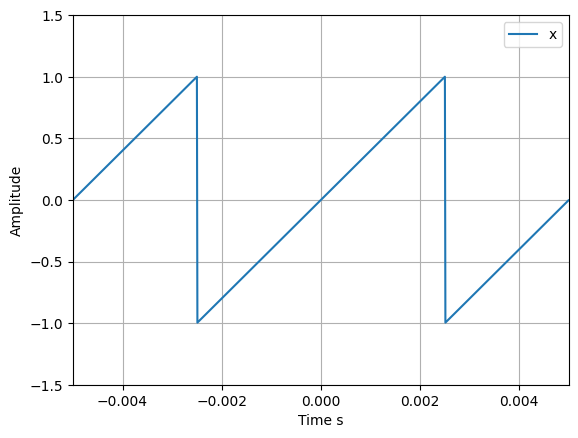

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

dt = 0.00001
t = np.arange(-0.005, 0.005, dt)

x = -1+(1/0.0025)*np.mod(t-0.0025, 0.005)

fig, ax = plt.subplots()

ax.plot(t, x, label='x')
ax.set_xlabel('Time s')
ax.set_ylabel('Amplitude')
ax.set_xlim(-0.005, 0.005)
ax.set_ylim(-1.5 , 1.5)

ax.legend()
ax.grid()

plt.show()

## Task 1b

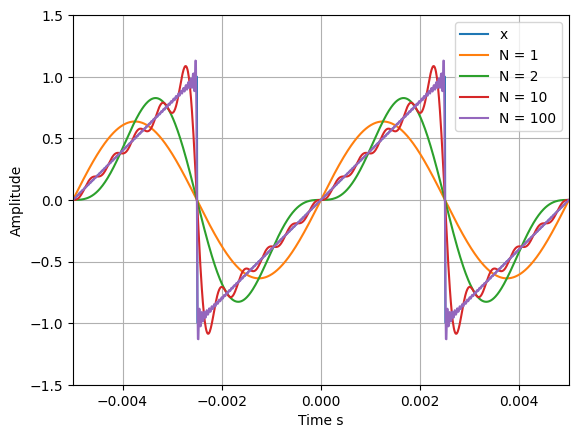

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

dt = 0.00001
t = np.arange(-0.005, 0.005, dt)
x = -1+(1/0.0025)*np.mod(t-0.0025, 0.005)

fig, ax = plt.subplots()
ax.plot(t, x, label='x')

N_val = [1, 2, 10, 100]
w = (2*np.pi) / 0.005

for N in N_val:
    n = np.arange(-N, N + 1)
    fs = 0

    for i in n:
        if i==0:
            cn = 0
        else:
            cn = ((-1.0)**i)*1j*(1/(i*np.pi))

        fs += (cn*np.exp(1j*i*w*t))
        
    if np.max(np.abs(np.imag(fs))) < 1e-12:
        fs = np.real(fs)
    ax.plot(t, fs, label=f'N = {N}')



ax.set_xlabel('Time s')
ax.set_ylabel('Amplitude')
ax.set_xlim(-0.005, 0.005)
ax.set_ylim(-1.5 , 1.5)

ax.legend()
ax.grid()

plt.show()

##With this graph we can observe that the larger the values on N are, the more the graph will move towards x.## When including more components N, higher frequencies will be included and the approximation will become more detailed, hence looking more like our original signal x. This also shows how lower frequencies gives smoother and wider looking plots, while higher frequensies gives tighter and sharper graphs.

## Task 1c

The signal is, as stated in the assignment, a periodic signal. That can be seen in the graph because the pattern repeats identically over time. By looking at the fourier transform table we can therefore see that the "T0-periodic" is the one we want to use:

$X(\omega ) = 2*np.pi\sum_{n} c_n \delta(\omega - n\omega_0)$

After applying the coefficients from the previous task, we get the new expression:

$X(\omega ) = 2*np.pi\sum_{n=-\infty}^{\infty} \left( (-1)^n j \frac{1}{n\pi} \right) \delta(\omega - n\omega_0)$   for n ≠ 0

/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/1513028333.py:9: RuntimeWarning: divide by zero encountered in divide
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))
/var/folders/19/k6h_ynnd2gqbcfhgqplml5hw0000gn/T/ipykernel_37622/1513028333.py:9: RuntimeWarning: invalid value encountered in multiply
  Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi))


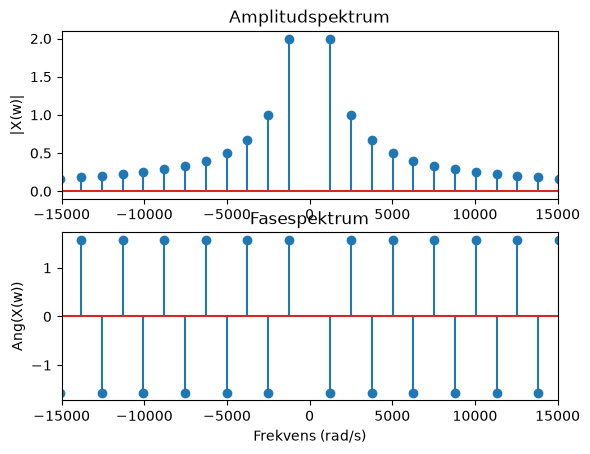

In [5]:
import numpy as np
import matplotlib.pyplot as plt

M = 100
n = np.arange( -M, M + 1, 1)
w = (2*np.pi)/0.005

wn = n * w
Xn = 2 * np.pi * ((-1.0)**n) * 1j * (1 /(n * np.pi)) 
#Xn[n == 0] = 0

fig, ax = plt.subplots(2, 1)
# Plot magnitude spectrum
ax[0].stem(wn, np.abs(Xn))
ax[0].set_xlim([-15e3, 15e3])
ax[0].set_title("Amplitudspektrum")
ax[0].set_ylabel("|X(w)|")
# Plot phase spectrum
ax[1].stem(wn, np.angle(Xn))
ax[1].set_xlim([-15e3, 15e3])
ax[1].set_title("Fasespektrum")
ax[1].set_ylabel("Ang(X(w))")
ax[1].set_xlabel("Frekvens (rad/s)")

plt.show()

From the obtained results of plotting the spectrum of the signal x we can see that the the spectrum consists of discrete spectral lines.  This is bacause the signal is periodic, meaning energy only exists at specific frequencies (wn= nw0). Additionally, there is no bar at w = 0, meaning the avarege value (DC component) is zero. 

Looking at the amplitude spectum we can see that low frequencies give the largest magintute and give the signal its main shape. While higher frequencies are smaller, creating the sharp edges of the sawtooth wave. 

Choosing N in Task 1b means choosing how many of these spectral lines to include. More lines (higher N) result in a sharper signal approximation.